# Hồi quy Đa thức (Polynomial Regression)

Mô hình hồi quy tuyến tính bị giới hạn bởi khả năng biểu diễn các quan hệ phức tạp. Bằng cách sử dụng các hàm cơ sở phi tuyến (nonlinear basis functions) $\phi_j(x)$[cite: 7], ta có thể giữ nguyên bản chất tối ưu tuyến tính theo trọng số $w$ nhưng vẫn biểu diễn được đường cong phi tuyến theo đầu vào $x$[cite: 8].

Phương trình hàm giả thuyết mở rộng bậc $M$[cite: 7]:
$$y(x, w) = w_0 + \sum_{j=1}^{M} w_j x^j = w^T \phi(x)$$

Vector đặc trưng mới sau khi biến đổi: $\phi(x) = [1, x, x^2, \dots, x^M]^T$.  
Việc giải bài toán hồi quy đa thức hoàn toàn tương đương với bài toán hồi quy tuyến tính đa biến thông thường trên tập dữ liệu đã được ánh xạ qua hàm $\phi$[cite: 7, 9].
Tuy nhiên, khi tăng bậc $M$ lên quá cao, mô hình sẽ gặp hiện tượng quá khớp (Overfitting), ghi nhớ cả nhiễu thay vì quy luật tổng quát của dữ liệu[cite: 7, 9].

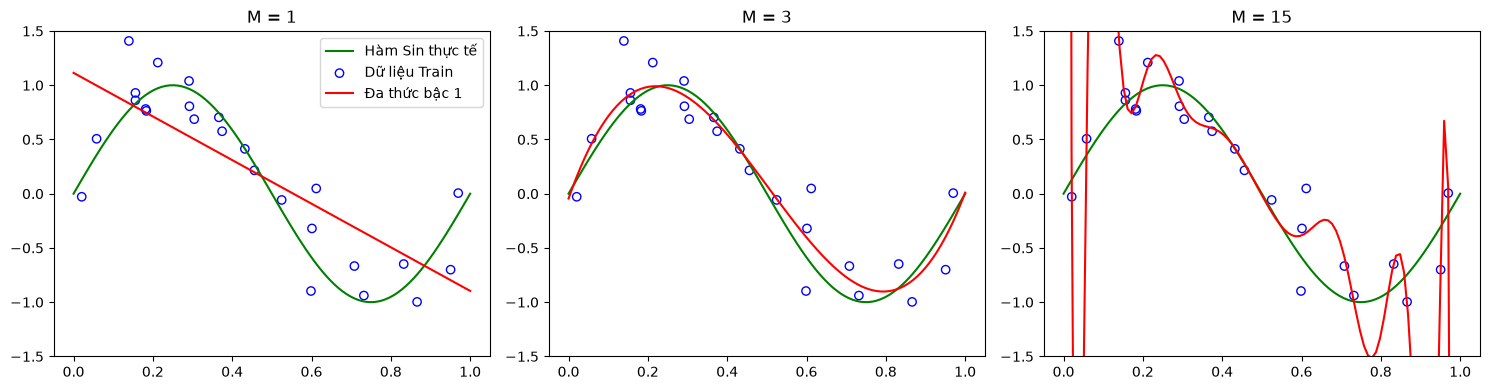

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from utils.preprocessing import PolynomialFeatures

# -------------------------------------------------------------------------
# Tái định nghĩa nhanh Class Linear Regression để phục vụ Hồi quy Đa thức
# -------------------------------------------------------------------------
class LinearRegressionNormalEq:
    def __init__(self, fit_intercept=True):
        self.fit_intercept = fit_intercept
        self.weights = None
        self.intercept = None

    def fit(self, X: np.ndarray, y: np.ndarray):
        X, y = np.asarray(X), np.asarray(y).reshape(-1, 1)
        Phi = np.hstack([np.ones((X.shape[0], 1), dtype=X.dtype), X]) if self.fit_intercept else X
        w_opt = np.linalg.pinv(Phi) @ y
        if self.fit_intercept:
            self.intercept = float(w_opt[0, 0])
            self.weights = w_opt[1:].flatten()
        else:
            self.intercept = 0.0
            self.weights = w_opt.flatten()
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        return np.asarray(X) @ self.weights + self.intercept

# -------------------------------------------------------------------------
# Thực nghiệm Overfitting
# -------------------------------------------------------------------------
# 1. Sinh dữ liệu hình Sin có nhiễu (Dựa trên tập dữ liệu kinh điển của Bishop - PRML)
np.random.seed(42)
N = 25
X_train = np.sort(np.random.rand(N, 1), axis=0)
y_train = np.sin(2 * np.pi * X_train).flatten() + np.random.randn(N) * 0.25

X_test = np.linspace(0, 1, 100).reshape(-1, 1)
y_true = np.sin(2 * np.pi * X_test).flatten()

# 2. Định nghĩa hàm huấn luyện và vẽ đồ thị cho từng bậc đa thức
def plot_polynomial_fit(degrees, X_train, y_train, X_test, y_true):
    plt.figure(figsize=(15, 4))
    
    for i, degree in enumerate(degrees):
        plt.subplot(1, len(degrees), i + 1)
        
        # Tiền xử lý tạo đặc trưng đa thức
        poly = PolynomialFeatures(degree=degree)
        X_train_poly = poly.fit_transform(X_train)
        X_test_poly = poly.transform(X_test)
        
        # Huấn luyện mô hình
        model = LinearRegressionNormalEq(fit_intercept=True)
        model.fit(X_train_poly, y_train)
        y_pred = model.predict(X_test_poly)
        
        # Trực quan hóa
        plt.plot(X_test, y_true, color='green', label='Hàm Sin thực tế')
        plt.scatter(X_train, y_train, color='blue', facecolors='none', label='Dữ liệu Train')
        plt.plot(X_test, y_pred, color='red', label=f'Đa thức bậc {degree}')
        
        plt.ylim(-1.5, 1.5)
        plt.title(f"M = {degree}")
        if i == 0: plt.legend()
        
    plt.tight_layout()
    plt.show()

# 3. Chạy thực nghiệm với bậc M = 1 (Underfit), M = 3 (Good Fit), M = 15 (Overfit)
plot_polynomial_fit(degrees=[1, 3, 15], X_train=X_train, y_train=y_train, X_test=X_test, y_true=y_true)